# L2_T2 — Label Mapping & Preprocessing: DermNet → Aura's Conditions
### Layer 2 of the Aura pipeline · Task 2 of N

**What this notebook does:** turns DermNet's 865 fine-grained disease labels into a small, reviewed set of
Aura condition categories, then preprocesses only the mapped images (face-detect-or-fallback + CLAHE, same as
Layer 1) and archives the result safely.

**Why the mapping is rule-based and printed, not hidden:** `L2_T1` showed the label list is messy (865 labels,
~200 with a single image, inconsistent casing, and a meaningless `IMG` label). Which labels count as "acne" or
"redness" is a judgment call. The rules below are explicit keyword rules with explicit exclusions, and **Step 3
prints exactly what each rule matched and dropped** so you can check it against what you know before anything
is processed. There is a `MANUAL_ADDITIONS` dict for fixing anything the rules get wrong.

**What DermNet can and cannot give Layer 2 — read this before trusting the output:**

| Aura condition | From DermNet? | Why |
|---|---|---|
| Acne | **Yes, partially** | Active-lesion labels (cystic, comedonal, pustular). Scarring, keloidalis and histology slides are excluded — they aren't what Aura's acne severity grading is about |
| Sensitivity / redness | **Partially** | Rosacea and perioral dermatitis are real redness conditions, but they're disease labels, not "reactive skin" |
| Hyperpigmentation | **Thin** | Only a few hundred images across a handful of labels |
| Dryness / oiliness | **No** | DermNet labels diseases, not skin-type traits. `sebaceous hyperplasia` is deliberately **not** treated as oiliness — it isn't |
| Pore visibility | **No** | Nothing in DermNet labels it |

**Two structural limits that matter more than the mapping:**
1. **One label per image, so no true multi-label data.** An image mapped to "acne" is *not* confirmed to be
   free of redness or pigmentation — those are *unknown*, not *negative*. Training must not treat the missing
   categories as zeros (use a masked loss, or train one-vs-rest on known labels only).
2. **No healthy-skin class exists here.** Every DermNet image shows some disease. A model trained only on this
   will never learn what "clear skin" looks like. That needs the skin-types dataset or in-house data.

**License reminder:** DermNet's Hugging Face mirror states no license. Everything here stays research-only
until that's verified (see `DATA_PROVENANCE_NOTICE.md` on Drive).

## Step 0 — Mount Drive, load the L2_T1 manifest, confirm the archive exists

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json

DRIVE_ROOT = "/content/drive/MyDrive/Projects/Aura/Layer2_SkinCondition"
MANIFEST_PATH = f"{DRIVE_ROOT}/manifest.json"

assert os.path.exists(MANIFEST_PATH), "manifest.json not found -- did L2_T1 finish and verify?"
with open(MANIFEST_PATH) as f:
    manifest = json.load(f)

DERMNET_ARCHIVE = manifest["datasets"]["dermnet"]["drive_archive"]
EXPECTED_IMAGES = manifest["datasets"]["dermnet"]["image_count"]
assert os.path.exists(DERMNET_ARCHIVE), f"Archive not found: {DERMNET_ARCHIVE}"
print(f"✅ DermNet archive found: {DERMNET_ARCHIVE}")
print(f"Expected image count: {EXPECTED_IMAGES}")

LOCAL_ROOT = "/content/aura_local/Layer2_SkinCondition"
LOCAL_EXTRACTED = f"{LOCAL_ROOT}/extracted"
LOCAL_ARCHIVES = "/content/aura_local/archives"
LOCAL_PP = f"{LOCAL_ROOT}/preprocessed/dermnet_conditions"
DRIVE_PP_DIR = f"{DRIVE_ROOT}/preprocessed"
for d in [LOCAL_EXTRACTED, LOCAL_ARCHIVES, LOCAL_PP, DRIVE_PP_DIR]:
    os.makedirs(d, exist_ok=True)


Mounted at /content/drive
✅ DermNet archive found: /content/drive/MyDrive/Projects/Aura/Layer2_SkinCondition/datasets/dermnet/dermnet.tar.gz
Expected image count: 15297


## Step 1 — Install dependencies

In [ ]:
!pip install -q mediapipe opencv-python-headless pandas pillow tqdm matplotlib
print("Dependencies installed.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 9.5 MB/s eta 0:00:00
Dependencies installed.


## Step 2 — Copy the archive to local disk first, then extract, then verify the count

Copy-first, extract-second — the same fix that avoided the Drive `Transport endpoint is not connected` crash
in Layer 1.

In [ ]:
import shutil, tarfile, time

local_archive = os.path.join(LOCAL_ARCHIVES, os.path.basename(DERMNET_ARCHIVE))
print("Copying archive from Drive to local disk...")
shutil.copy2(DERMNET_ARCHIVE, local_archive)
assert os.path.getsize(local_archive) == os.path.getsize(DERMNET_ARCHIVE), "Copy size mismatch"
print(f"  ✅ Copied ({os.path.getsize(local_archive)/1e6:.1f} MB)")

print("Extracting...")
with tarfile.open(local_archive, "r:gz") as tar:
    tar.extractall(LOCAL_EXTRACTED, filter="data")

LOCAL_DERMNET_DIR = f"{LOCAL_EXTRACTED}/dermnet"
LOCAL_IMG_DIR = f"{LOCAL_DERMNET_DIR}/train"
n_imgs = len([f for f in os.listdir(LOCAL_IMG_DIR) if f.endswith(".jpg")])
print(f"Extracted {n_imgs} images (expected {EXPECTED_IMAGES})")
assert n_imgs == EXPECTED_IMAGES, "Extracted count does not match the manifest -- do not continue."
print("✅ Extraction verified.")


Copying archive from Drive to local disk...
  ✅ Copied (1559.6 MB)
Extracting...
Extracted 15297 images (expected 15297)
✅ Extraction verified.


## Step 3 — Normalize the labels, apply the mapping rules, and PRINT what happened

**Stop and read this cell's output before running anything after it.** It shows, per Aura category: every
label that was kept (with its image count), and every label that matched an include rule but was dropped by an
exclusion (and why).

A label that matches one category's include rule but hits that category's exclusion is **not** discarded
immediately — it falls through to the remaining categories first (so `acne rosacea`, for example, can still
land in redness). It is only dropped if no category accepts it.

In [ ]:
import pandas as pd
import re

labels_df = pd.read_csv(f"{LOCAL_DERMNET_DIR}/train_labels.csv")
print(f"Loaded {len(labels_df)} rows, {labels_df['label'].nunique()} distinct raw labels")

def normalize(label):
    return re.sub(r"\s+", " ", str(label).strip().lower())

labels_df["label_norm"] = labels_df["label"].apply(normalize)
print(f"After normalizing case/whitespace: {labels_df['label_norm'].nunique()} distinct labels "
      f"(merges variants like 'Acne' / 'acne')")

# ---- Mapping rules: substring include, substring exclude. First category that ACCEPTS the label wins. ----
CATEGORY_RULES = {
    "acne": {
        "include": ["acne", "comedo"],
        # Scarring, keloidalis (a scalp/neck follicle condition) and microscope slides are not what
        # Aura's active-acne severity grading is about. 'rosacea' is excluded here so that
        # 'acne rosacea'-style labels fall through to the redness category instead.
        "exclude": ["keloidalis", "scar", "histology", "rosacea"],
    },
    "redness_sensitivity": {
        "include": ["rosacea", "perioral"],
        "exclude": ["rhinophyma", "histology"],
    },
    "pigmentation": {
        "include": ["lentigo", "sun damaged", "melasma", "freckle", "pigment", "hyperpig", "ephelid"],
        # Cancers, moles and systemic/genetic pigment disorders are not cosmetic hyperpigmentation.
        "exclude": ["maligna", "melanoma", "melanocytic", "nevi", "nevus", "incontinentia",
                    "purpuric", "histology"],
    },
}
EXACT_DROP = {"img"}  # 'IMG' (119 images) carries no diagnostic meaning

# Anything the rules got wrong can be fixed here, after reviewing the printed output below.
# Format: {"normalized label text": "acne" | "redness_sensitivity" | "pigmentation" | None}
# None = force-exclude. Example: MANUAL_ADDITIONS = {"seborrheic dermatitis": "redness_sensitivity"}
MANUAL_ADDITIONS = {}

def map_label(lab):
    """Returns (category or None, reason)."""
    if lab in MANUAL_ADDITIONS:
        return MANUAL_ADDITIONS[lab], "manual override"
    if lab in EXACT_DROP:
        return None, "dropped: uninformative label"
    exclusion_note = None
    for cat, rule in CATEGORY_RULES.items():
        if any(k in lab for k in rule["include"]):
            hit_exclude = [k for k in rule["exclude"] if k in lab]
            if hit_exclude:
                # Remember why, but keep looking -- a later category may still accept it.
                exclusion_note = exclusion_note or f"matched '{cat}' but excluded by '{hit_exclude[0]}'"
                continue
            return cat, "rule match"
    if exclusion_note:
        return None, exclusion_note
    return None, "unmapped"

mapped = labels_df["label_norm"].apply(map_label)
labels_df["aura_condition"] = [m[0] for m in mapped]
labels_df["map_reason"] = [m[1] for m in mapped]

label_table = (labels_df.groupby(["label_norm", "aura_condition", "map_reason"], dropna=False)
               .size().reset_index(name="n_images"))

for cat in CATEGORY_RULES:
    sub = label_table[label_table["aura_condition"] == cat].sort_values("n_images", ascending=False)
    print(f"\n{'='*60}\n{cat.upper()}: {sub['n_images'].sum()} images across {len(sub)} labels\n{'='*60}")
    print(sub[["label_norm", "n_images"]].to_string(index=False))

dropped = label_table[label_table["map_reason"].str.startswith("matched") |
                       label_table["map_reason"].str.startswith("dropped")]
print(f"\n{'='*60}\nMATCHED AN INCLUDE RULE BUT DROPPED (check these are right to drop)\n{'='*60}")
print(dropped.sort_values("n_images", ascending=False)[["label_norm", "map_reason", "n_images"]].to_string(index=False))


Loaded 15297 rows, 865 distinct raw labels
After normalizing case/whitespace: 814 distinct labels (merges variants like 'Acne' / 'acne')

ACNE: 374 images across 15 labels
         label_norm  n_images
        acne cystic       120
   acne open comedo        70
      acne pustular        69
 acne closed comedo        41
    acne excoriated        26
     acne infantile        15
  actinic comedones        13
acne primary lesion         6
  nevus comedonicus         6
     anal comedones         2
               acne         2
     acne mechanica         1
     comedones ears         1
      comedonesears         1
      giantcomedone         1

REDNESS_SENSITIVITY: 311 images across 20 labels
           label_norm  n_images
  perioral dermatitis       109
              rosacea       106
         rosacea nose        61
      rosacea steroid         7
             rosaceak         7
            rosaceaok         4
         perioralderm         2
       steroidrosacea         2
rosacea gr

In [ ]:
# Candidates the rules did NOT map, that might deserve a second look. This is a prompt for your judgment,
# not an automatic include -- many 'dermatitis' labels are not facial redness conditions at all.
REVIEW_KEYWORDS = ["dermatitis", "erythema", "telangiect", "flush", "redness", "dark spot", "melan"]
unmapped = label_table[label_table["map_reason"] == "unmapped"]
review = unmapped[unmapped["label_norm"].apply(lambda l: any(k in l for k in REVIEW_KEYWORDS))]
print(f"{len(review)} unmapped labels contain a review keyword (top 40 by image count):\n")
print(review.sort_values("n_images", ascending=False).head(40)[["label_norm", "n_images"]].to_string(index=False))
print("\nIf any of these should be included, add them to MANUAL_ADDITIONS in the cell above and re-run it.")


35 unmapped labels contain a review keyword (top 40 by image count):

                                label_norm  n_images
                       erythema multiforme       103
                        malignant melanoma       101
                         stasis dermatitis       100
                          melanocytic nevi        85
                  dermatitis herpetiformis        78
                     seborrheic dermatitis        65
               chondrodermatitis nodularis        64
                           telangiectasias        48
                          erythema nodosum        39
                      erythema infectiosum        30
                          erythema ab igne        20
                            melanoma mimic        18
             erythema annulare centrifugum        15
     interstitial granulomatous dermatitis        15
          idiopathic guttate hypomelanosis        13
                          melanotic macule         9
                    caterpill

**Checkpoint:** if the printed lists look right, continue. If something is wrong — a label sitting in the
wrong category, or an obvious facial-redness label stuck in the "unmapped" review list — edit
`MANUAL_ADDITIONS` (or the rules) in the mapping cell, re-run it and the review cell, and only then move on.
Everything downstream depends on this mapping.

## Step 4 — Summarize the mapped dataset and check whether each category is big enough to matter

In [ ]:
mapped_df = labels_df[labels_df["aura_condition"].notna()].copy()
cat_counts = mapped_df["aura_condition"].value_counts()
print(f"Mapped images: {len(mapped_df)} of {len(labels_df)} ({100*len(mapped_df)/len(labels_df):.1f}% of DermNet)")
print(cat_counts.to_string())

assert len(mapped_df) > 0, "No images mapped -- check the rules in Step 3."

MIN_PER_CATEGORY = 100
for cat in CATEGORY_RULES:
    n = int(cat_counts.get(cat, 0))
    if n == 0:
        print(f"⚠️  {cat}: ZERO images -- this condition has no DermNet training data at all.")
    elif n < MIN_PER_CATEGORY:
        print(f"⚠️  {cat}: only {n} images (< {MIN_PER_CATEGORY}) -- too thin to train on alone.")
print("\nNote: dryness/oiliness and pore visibility have no mapping at all -- see the table at the top.")


Mapped images: 983 of 15297 (6.4% of DermNet)
aura_condition
acne                   374
redness_sensitivity    311
pigmentation           298

Note: dryness/oiliness and pore visibility have no mapping at all -- see the table at the top.


## Step 5 — Define the preprocessing function (same pipeline as Layer 1)

MediaPipe's current Tasks API for face detection (the legacy `mp.solutions` API was removed from current
releases), then crop-with-margin or full-image fallback, resize to 224×224, and CLAHE on the L channel only.
DermNet photos are not selfies — many show other body parts — so "no face found, use the whole image" is an
expected path here, not an error.

In [ ]:
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision
from PIL import Image

IMG_SIZE = 224
model_path = "/content/aura_local/blaze_face_short_range.tflite"
if not os.path.exists(model_path):
    import urllib.request
    urllib.request.urlretrieve(
        "https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/1/blaze_face_short_range.tflite",
        model_path,
    )
detector = mp_vision.FaceDetector.create_from_options(
    mp_vision.FaceDetectorOptions(base_options=mp_python.BaseOptions(model_asset_path=model_path))
)

def preprocess_image(img_rgb, margin_ratio=0.25):
    """Returns (processed 224x224 RGB, face_detected)."""
    h, w = img_rgb.shape[:2]
    result = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=img_rgb))
    face_found = bool(result.detections)
    if face_found:
        bbox = result.detections[0].bounding_box
        mx, my = int(bbox.width * margin_ratio), int(bbox.height * margin_ratio)
        x1, y1 = max(0, bbox.origin_x - mx), max(0, bbox.origin_y - my)
        x2, y2 = min(w, bbox.origin_x + bbox.width + mx), min(h, bbox.origin_y + bbox.height + my)
        if x2 > x1 and y2 > y1:
            crop = img_rgb[y1:y2, x1:x2]
        else:
            crop, face_found = img_rgb, False
    else:
        crop = img_rgb
    resized = cv2.resize(crop, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(resized, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return cv2.cvtColor(cv2.merge([clahe.apply(l), a, b]), cv2.COLOR_LAB2RGB), face_found

def load_rgb(path):
    return np.array(Image.open(path).convert("RGB"))
print("Preprocessing function ready.")


Preprocessing function ready.


## Step 6 — Visual QA before processing everything

Three random samples per category, original next to processed. Look at them: do the "acne" images actually show
acne, do the "redness" images show redness, does the CLAHE step look reasonable rather than washed out? If a
category looks wrong, go back to Step 3 and fix the mapping first.

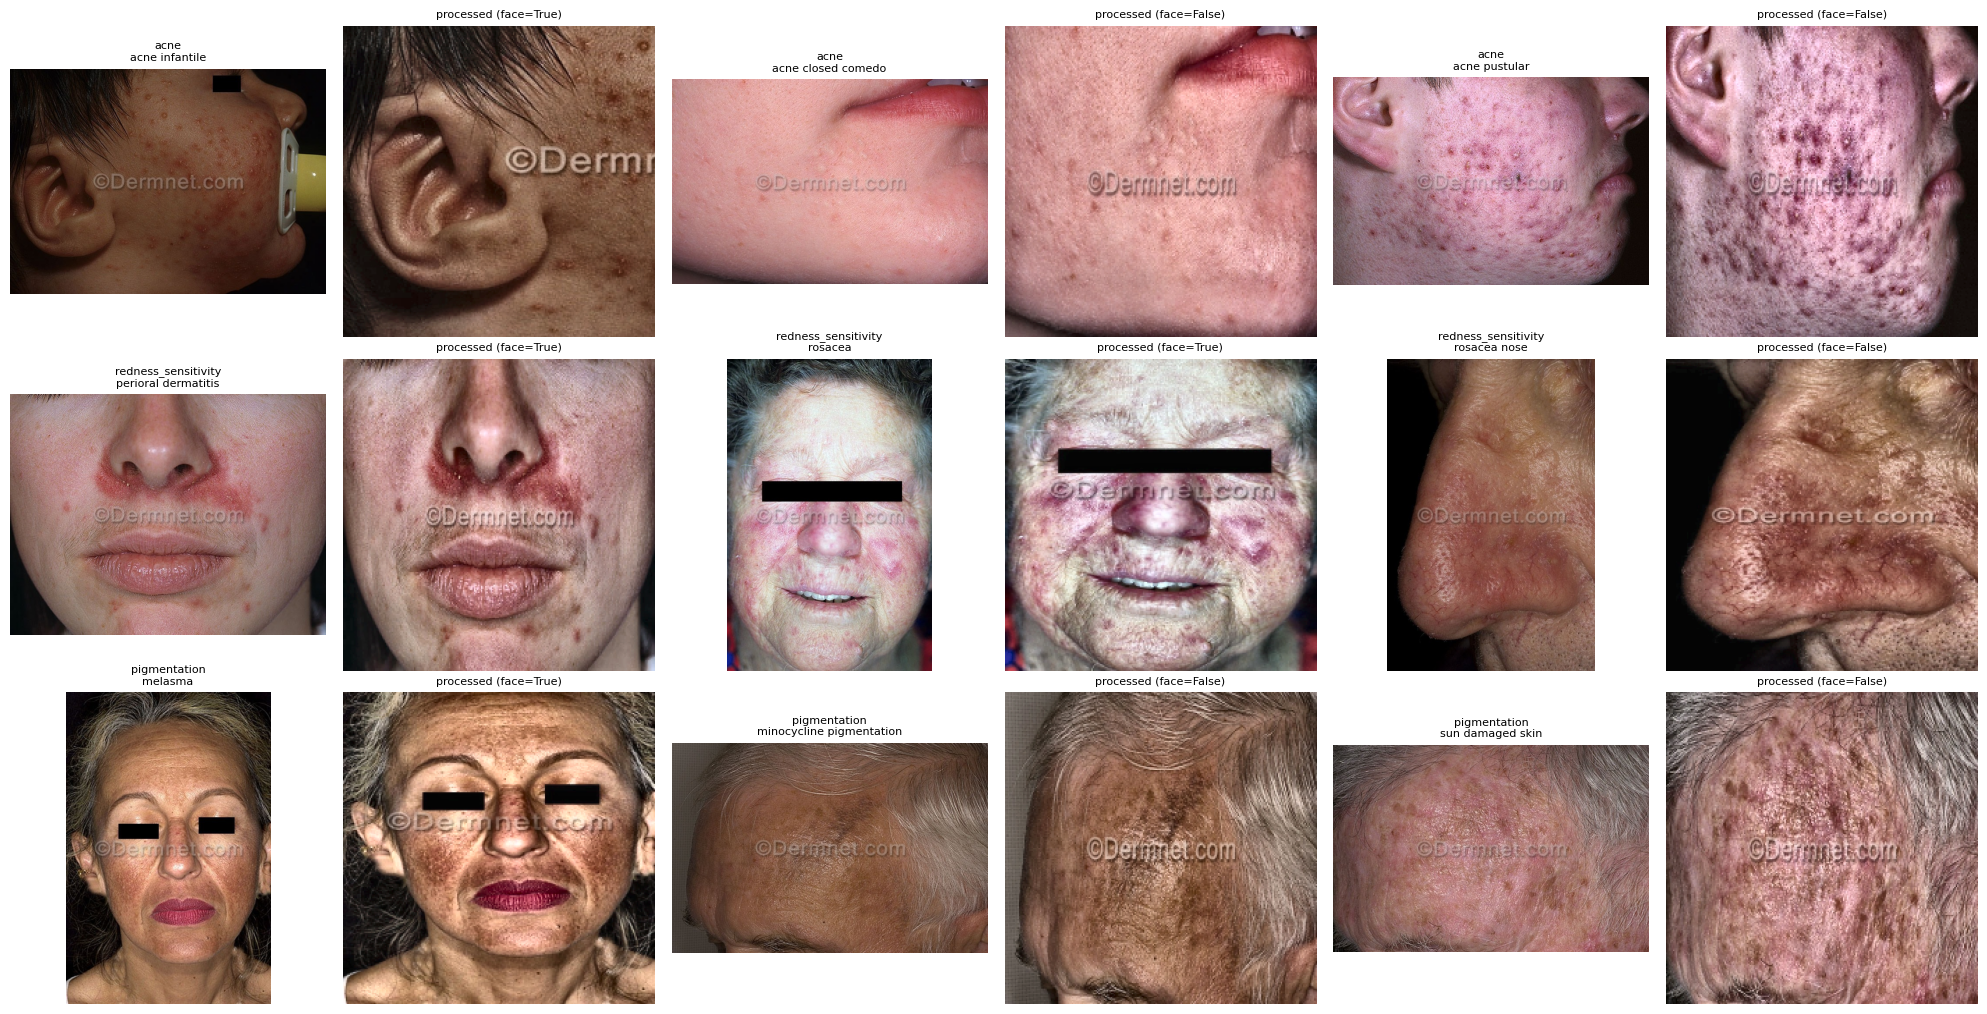

In [ ]:
import matplotlib.pyplot as plt

cats = [c for c in CATEGORY_RULES if (mapped_df["aura_condition"] == c).any()]
fig, axes = plt.subplots(len(cats), 6, figsize=(20, 3.4 * len(cats)))
if len(cats) == 1:
    axes = np.array([axes])

for r, cat in enumerate(cats):
    sample = mapped_df[mapped_df["aura_condition"] == cat].sample(
        min(3, (mapped_df["aura_condition"] == cat).sum()), random_state=7)
    for c, (_, row) in enumerate(sample.iterrows()):
        orig = load_rgb(os.path.join(LOCAL_IMG_DIR, row["filename"]))
        proc, found = preprocess_image(orig)
        axes[r, c*2].imshow(orig); axes[r, c*2].axis("off")
        axes[r, c*2].set_title(f"{cat}\n{row['label_norm'][:28]}", fontsize=8)
        axes[r, c*2+1].imshow(proc); axes[r, c*2+1].axis("off")
        axes[r, c*2+1].set_title(f"processed (face={found})", fontsize=8)
plt.tight_layout()
plt.show()


**Checkpoint:** only continue if the samples look like what their category claims. A mislabeled category
here becomes a mislabeled training signal later, and nothing downstream will catch it.

## Step 7 — Preprocess every mapped image (to LOCAL disk)

In [ ]:
from tqdm.auto import tqdm

records, errors = [], 0
for _, row in tqdm(mapped_df.iterrows(), total=len(mapped_df), desc="Preprocessing mapped DermNet images"):
    out_path = os.path.join(LOCAL_PP, row["filename"])
    try:
        if os.path.exists(out_path):
            face_found = None  # already processed this session; not re-checked
        else:
            proc, face_found = preprocess_image(load_rgb(os.path.join(LOCAL_IMG_DIR, row["filename"])))
            Image.fromarray(proc).save(out_path, "JPEG", quality=92)
        records.append({
            "processed_filename": row["filename"],
            "aura_condition": row["aura_condition"],
            "original_label": row["label"],
            "label_norm": row["label_norm"],
            "face_detected": face_found,
        })
    except Exception as e:
        errors += 1
        print(f"  Skipped {row['filename']}: {type(e).__name__}: {e}")

pp_df = pd.DataFrame(records)
pp_csv = os.path.join(LOCAL_PP, "processed_labels.csv")
pp_df.to_csv(pp_csv, index=False)

print(f"\nProcessed {len(pp_df)} images, {errors} errors")
known = pp_df["face_detected"].notna()
print("\nFace-detected rate by category (rest used the whole-image fallback):")
for cat in CATEGORY_RULES:
    sub = pp_df[(pp_df["aura_condition"] == cat) & known]
    if len(sub):
        print(f"  {cat}: {(sub['face_detected'] == True).mean()*100:.1f}% of {len(sub)}")


Preprocessing mapped DermNet images:   0%|          | 0/983 [00:00<?, ?it/s]


Processed 983 images, 0 errors

Face-detected rate by category (rest used the whole-image fallback):
  acne: 28.3% of 374
  redness_sensitivity: 42.1% of 311
  pigmentation: 16.8% of 298


## Step 8 — Archive, upload to Drive, and verify

In [ ]:
def archive_and_upload(local_dir, archive_filename, drive_dest_dir, arcname=None):
    local_archive_path = os.path.join("/content/aura_local", archive_filename)
    arcname = arcname or os.path.basename(local_dir.rstrip("/"))
    with tarfile.open(local_archive_path, "w:gz") as tar:
        tar.add(local_dir, arcname=arcname)
    local_size = os.path.getsize(local_archive_path)
    drive_archive_path = os.path.join(drive_dest_dir, archive_filename)
    shutil.copy2(local_archive_path, drive_archive_path)
    time.sleep(2)
    drive_size = os.path.getsize(drive_archive_path)
    if drive_size != local_size:
        raise RuntimeError(f"SIZE MISMATCH: local={local_size}, drive={drive_size}")
    print(f"✅ {archive_filename}: {drive_size/1e6:.1f} MB verified on Drive")
    return drive_archive_path, drive_size

pp_drive_path, pp_drive_size = archive_and_upload(
    LOCAL_PP, "dermnet_conditions_preprocessed.tar.gz", DRIVE_PP_DIR, arcname="dermnet_conditions_preprocessed")


✅ dermnet_conditions_preprocessed.tar.gz: 22.8 MB verified on Drive


In [ ]:
drive.flush_and_unmount()
print("Drive unmounted -- forced sync.")
time.sleep(3)
drive.mount('/content/drive')

if os.path.exists(pp_drive_path) and os.path.getsize(pp_drive_path) == pp_drive_size:
    print(f"✅ Confirmed after fresh remount: {os.path.basename(pp_drive_path)} ({pp_drive_size/1e6:.1f} MB)")
else:
    print("❌ Archive missing or wrong size after remount -- do NOT close this session; re-run Step 8.")

with tarfile.open(pp_drive_path, "r:gz") as tar:
    members = tar.getmembers()
    n_jpg = len([m for m in members if m.name.endswith(".jpg")])
    last = tar.extractfile(members[-1])
    _ = last.read() if last else b""
print(f"Archive holds {n_jpg} images (expected {len(pp_df)})")
assert n_jpg == len(pp_df), "Archive image count does not match what was processed."
print("✅ Archive structurally complete.")


Drive unmounted -- forced sync.
Mounted at /content/drive
✅ Confirmed after fresh remount: dermnet_conditions_preprocessed.tar.gz (22.8 MB)
Archive holds 983 images (expected 983)
✅ Archive structurally complete.


## Step 9 — Update the manifest (last, only after verification passed)

In [ ]:
from datetime import datetime, timezone

manifest["label_mapping"] = {
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "method": "keyword include/exclude rules over normalized DermNet labels, reviewed by printed output",
    "rules": CATEGORY_RULES,
    "manual_additions": MANUAL_ADDITIONS,
    "images_per_category": {k: int(v) for k, v in pp_df["aura_condition"].value_counts().items()},
    "not_covered": ["dryness_oiliness", "pore_visibility"],
    "structural_limits": [
        "One label per image: absent categories are UNKNOWN, not negative -- train with a masked/one-vs-rest loss.",
        "No healthy-skin class exists in DermNet.",
    ],
}
manifest["preprocessing"] = {
    "drive_archive": pp_drive_path,
    "archive_size_mb": round(pp_drive_size / 1e6, 1),
    "images_processed": int(len(pp_df)),
    "errors": int(errors),
    "target_image_size": IMG_SIZE,
    "labels_csv_inside_archive": "dermnet_conditions_preprocessed/processed_labels.csv",
}

with open(MANIFEST_PATH, "w") as f:
    json.dump(manifest, f, indent=2)
print(json.dumps({k: manifest[k] for k in ["label_mapping", "preprocessing"]}, indent=2, default=str))


{
  "label_mapping": {
    "generated_at_utc": "2026-10-13T05:02:38.129029+00:00",
    "method": "keyword include/exclude rules over normalized DermNet labels, reviewed by printed output",
    "rules": {
      "acne": {
        "include": [
          "acne",
          "comedo"
        ],
        "exclude": [
          "keloidalis",
          "scar",
          "histology",
          "rosacea"
        ]
      },
      "redness_sensitivity": {
        "include": [
          "rosacea",
          "perioral"
        ],
        "exclude": [
          "rhinophyma",
          "histology"
        ]
      },
      "pigmentation": {
        "include": [
          "lentigo",
          "sun damaged",
          "melasma",
          "freckle",
          "pigment",
          "hyperpig",
          "ephelid"
        ],
        "exclude": [
          "maligna",
          "melanoma",
          "melanocytic",
          "nevi",
          "nevus",
          "incontinentia",
          "purpuric",
          "hi

## Done — what to do next

- A reviewed, small, preprocessed set of DermNet images now exists for acne, redness/sensitivity and
  pigmentation, archived and verified on Drive. Dryness/oiliness and pore visibility have **no data yet**.
- **The next real decision isn't another notebook — it's how to cover the gap.** Options: the Kaggle
  Oily/Dry/Normal skin-types set (whole-image skin-type labels; still needs downloading and a license check),
  ACNE04 for a stronger acne-severity head (academic-use only unless the authors grant permission), and
  eventually in-house per-zone labels.
- Next notebook: **`L2_T3` — Model Training.** It must use a masked or one-vs-rest loss (see the structural
  limits above), and should be expected to produce a weak model: a few hundred images per condition, one
  label per image, no healthy-skin examples.


# L2_T2 Task Summary: DermNet Label Mapping and Preprocessing

## Goal
Turn the raw DermNet archive from L2_T1 into a small, labelled, preprocessed image set mapped to Aura's Layer 2 categories. This is the input for L2_T3 training.

## Process
1. Mounted Drive, loaded the L2_T1 archive, and copied it to local disk. Extracted 15,297 images, matching the manifest.
2. Normalized label case and whitespace. This merged 865 raw labels into 814.
3. Applied keyword include/exclude rules to map labels to `acne`, `redness_sensitivity`, and `pigmentation`.
4. Printed the matched and dropped labels, plus unmapped labels containing review keywords, and checked them by eye.
5. Preprocessed the mapped images: MediaPipe face crop with a full-image fallback, resize to 224×224, CLAHE on the LAB L channel.
6. Archived the result, uploaded it to Drive, remounted, and verified size and contents. Then updated the manifest.

## Accomplished
| Item | Result |
|---|---|
| Source images | 15,297 (extraction verified) |
| Mapped images | **983** (6.4% of DermNet) |
| acne | 374 |
| redness_sensitivity | 311 |
| pigmentation | 298 |
| Preprocessing errors | 0 of 983 |
| Output archive | `preprocessed/dermnet_conditions_preprocessed.tar.gz`, 22.8 MB |
| Drive verification | Confirmed after a fresh remount; archive holds 983 images |
| Manifest | Updated with `label_mapping` and `preprocessing` |

Face-detection rate (the rest used the whole-image fallback):
- acne: 28.3%
- redness_sensitivity: 42.1%
- pigmentation: 16.8%

## Not Included, and Why
- **Dryness/oiliness and pore visibility:** DermNet has no labels for them. They need in-house or other data.
- **Healthy-skin class:** none exists in DermNet.
- **Zone annotations (forehead, cheeks, and so on):** none exist.
- **Dropped on purpose:**
  - Uninformative label `img`: 125 images.
  - `acne keloidalis`: 49. It is a different condition.
  - `lentigo maligna`: 23. It is pre-malignant.
  - Acne scars: 11.
  - `acne histology`: 2.
  - `nevus repigmented`: 2.
- **Unmapped labels with review keywords (35):** left out. Examples are seborrheic dermatitis, telangiectasias, and stasis dermatitis. Melanoma and nevi were excluded deliberately. I did not add any via `MANUAL_ADDITIONS`.

## Known Issues to Address Before Training
1. **The pigmentation set is contaminated.** 69 of its 298 images are not benign pigmentation:
   - `basal cell carcinoma pigmented`: 60.
   - `actinic keratosis pigmented`: 9.
   
   Pigmented BCC is a skin cancer. Neither belongs in a cosmetic pigmentation class. Excluding them would leave about 229, and `pigmented bands` (8) is also doubtful. `minocycline pigmentation` (15) is a drug-induced discoloration and is arguable. Add `basal cell`, `carcinoma` and `keratosis` to the pigmentation exclude list, then re-run.
2. **The acne set includes `nevus comedonicus` (6).** It is a nevus, not acne, so it should probably be excluded.
3. **Labels are one per image.** A missing label means unknown, not negative. L2_T3 must use a masked or one-vs-rest loss.
4. **The dataset is small and clinical.** About 1,000 images, many of them close-ups, so the model is not validated for selfie-style input. Only 17–42% of images had a detectable face.
5. **Licensing:** the DermNet mirror states no license. Treat it as research-only.

## Status
The mapped DermNet set is preprocessed, verified, and ready. Clean the pigmentation and acne labels (issues 1 and 2) before L2_T3.

## Next
L2_T3 trains the first condition model on this set with a masked loss.